In [1]:
!pip -q install keras-nlp
!pip -q install kagglehub[pandas-datasets]
!pip -q install spacy
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 5.5 MB/s eta 0:00:00


In [16]:
!python -m spacy download en_core_web_md

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 55.6 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import kagglehub
from kagglehub import KaggleDatasetAdapter
from sklearn.utils import class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from collections import Counter
import spacy
import pandas as pd
from sklearn.utils import resample
from IPython.display import display, HTML
import builtins
from pathlib import Path
import keras_tuner as kt
from tqdm import tqdm
import json
import keras_hub

In [3]:
from google.colab import drive
drive.mount('/content/drive')

drive_root = Path("/content/drive/MyDrive/Personal/Universidad/8° Semestre/RN/Entrega 2")
drive_root.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [15]:
# Carga del modelo de lenguaje de spaCy (en inglés, tamaño medio, incluye vectores)
nlp = spacy.load("en_core_web_md")

def spacy_preprocess(text):
    # Procesa el texto con el modelo de spaCy, dividiéndolo en tokens, detectando POS, etc.
    doc = nlp(text)

    # Lista de tokens preprocesados mediante lematización, minúsculas, y filtros
    tokens = [
        token.lemma_.lower()
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and token.lemma_ != '-PRON-'
    ]

    # Une los tokens en una cadena de texto preprocesado
    return " ".join(tokens)

OSError: [E050] Can't find model 'en_core_web_md'. It doesn't seem to be a Python package or a valid path to a data directory.

In [17]:
# Descarga y carga el dataset de reseñas de Yelp desde Kaggle usando kagglehub
kagglehub.dataset_download('omkarsabnis/yelp-reviews-dataset')
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "omkarsabnis/yelp-reviews-dataset",
    "yelp.csv",
)

# Conservamos únicamente las columnas necesarias: el texto de la reseña y su puntuación
df = df[['text', 'stars']]

# Se convierte a string explícitamente y se aplica lematización + limpieza a cada reseña
df['text'] = df['text'].astype(str).apply(spacy_preprocess)
df = df[df['text'].str.strip() != ""]

# Se añade una nueva columna con el número de tokens (palabras) por reseña
df['token_count'] = df['text'].astype(str).apply(lambda txt: len(txt.split()))

# Se guarda el DataFrame limpio y procesado en formato Parquet para uso posterior eficiente
df.to_parquet(drive_root / "yelp_reviews_preprocessed.parquet")

/tmp/ipython-input-17-2254767204.py:3: DeprecationWarning: load_dataset is deprecated and will be removed in a future version.
  df = kagglehub.load_dataset(


NameError: name 'spacy_preprocess' is not defined

In [18]:
def prepare_data(cfg, parquet_path="yelp_reviews_preprocessed.parquet", n_rows=None):
    # Cargar DF ya preprocesado
    # Se carga un DataFrame preprocesado guardado en formato Parquet.
    # Este archivo debe contener las columnas 'text', 'stars' y 'token_count'.
    if n_rows is not None:
        df = pd.read_parquet(drive_root / parquet_path).sample(n=n_rows, random_state=42)
    else:
        df = pd.read_parquet(drive_root / parquet_path)

    df['text'] = df['text'].str.replace(r'\s+', ' ', regex=True)

    df['text'] = df['text'].str.replace(r'\s+', ' ', regex=True)

    # Etiquetado
    if cfg["mode"] == "binary":
        # Si el modo es binario, se agrupan las clases:
        # estrellas 1-3 → 0 (negativas), estrellas 4-5 → 1 (positivas)
        df = df[df["stars"].isin([1, 2, 3, 4, 5])].copy()
        df["label"] = df["stars"].apply(lambda s: 0 if s <= 3 else 1)
        num_classes = 1  # solo una clase de salida (sigmoid)
    else:
        # Si el modo es multiclase, se asigna un valor 0-4 a cada estrella
        df = df.copy()
        df["label"] = df["stars"] - 1
        num_classes = 5  # 5 clases de salida (softmax)

    # Balanceo de clases
    if cfg["balance"]:
        # Se calcula el número objetivo de muestras por clase (120% del mínimo)
        min_c = df["label"].value_counts().min()
        target = int(min_c * 1.2)

        dfs = []
        for lab in df["label"].unique():
            # Para cada clase, se genera un DataFrame filtrado
            cls_df = df[df["label"] == lab]

            if len(cls_df) > target:
                # Si la clase tiene más muestras que el objetivo, se submuestrea
                cls_df = resample(
                    cls_df,
                    replace=False,  # sin reemplazo para submuestreo
                    n_samples=target,
                    random_state=42
                )

            dfs.append(cls_df)
        # Se combinan todas las clases y se reordenan aleatoriamente
        df = pd.concat(dfs).sample(frac=1, random_state=42)

    # División en train / validation / test
    # Primero se separa un 10% para test
    x_temp, x_test, y_temp, y_test = train_test_split(
        df["text"], df["label"],
        test_size=0.10,
        random_state=42
    )

    # Luego se separa un 10% de lo restante para validación
    x_train, x_val, y_train, y_val = train_test_split(
        x_temp, y_temp,
        test_size=0.10,
        random_state=42
    )

    # Conversión a tf.data.Dataset
    # Se crean datasets de TensorFlow a partir de los textos y etiquetas
    train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train))
    val_ds   = tf.data.Dataset.from_tensor_slices((x_val, y_val))
    test_ds  = tf.data.Dataset.from_tensor_slices((x_test, y_test))

    # Cálculo de class_weight (opcional)
    if cfg["use_weights"]:
        # Se calcula un peso inversamente proporcional a la frecuencia de cada clase
        w = class_weight.compute_class_weight(
            class_weight='balanced',
            classes=np.unique(y_train),
            y=np.array(y_train)
        )
        cw = dict(enumerate(w))  # se convierte a diccionario para pasarlo a model.fit
    else:
        cw = None

    # Retorno
    # Se retorna: datasets (train, val, test), los pesos, el número de clases
    # y la longitud máxima (percentil 85) para truncamiento posterior
    return train_ds, val_ds, test_ds, cw, num_classes, int(round(np.percentile(df['token_count'], 85))), df['text']

In [19]:
def format_class(k, mode):
    if mode == "binary":
        return "Negativa (0)" if k == 0 else "Positiva (1)"
    else:
        return f"{'★' * (k + 1)}{'☆' * (4 - k)} ({k})"

def print_class_distribution(counter, label, mode):
    print(f"{label}:")
    for k in sorted(counter.keys()):
        print(f"  Clase {k} – {format_class(k, mode)}: {counter[k]} ejemplos")

def sanity_check_prepare_data(train_ds, val_ds, test_ds, cw, num_classes, max_len, features):
    """
    Verifica la integridad del output de prepare_data, incluyendo distribución
    de etiquetas, tamaños de particiones y longitud de secuencia.
    """
    print("✅ Iniciando verificación de datos...\n")

    # 1. Verificación de columnas mínimas
    expected_cols = {"text", "stars", "token_count"}
    parquet_cols  = pd.read_parquet(drive_root / "yelp_reviews_preprocessed.parquet").columns
    assert expected_cols.issubset(parquet_cols), (
        f"❌ Faltan columnas requeridas: {expected_cols - set(parquet_cols)}"
    )

    # 2. Extraer etiquetas de cada dataset
    y_train = [y.numpy() for _, y in train_ds]
    y_val   = [y.numpy() for _, y in val_ds]
    y_test  = [y.numpy() for _, y in test_ds]

    # 3. Distribución de clases
    c_train = Counter(y_train)
    c_val   = Counter(y_val)
    c_test  = Counter(y_test)
    c_total = c_train + c_val + c_test

    # 3. Distribución de clases con descripción
    print("📊 Distribución de etiquetas:")
    print_class_distribution(c_train, "🟩 Train", mode="binary" if num_classes == 1 else "multiclass")
    print_class_distribution(c_val,   "🟨 Val",   mode="binary" if num_classes == 1 else "multiclass")
    print_class_distribution(c_test,  "🟥 Test",  mode="binary" if num_classes == 1 else "multiclass")
    print_class_distribution(c_total, "🧮 Total", mode="binary" if num_classes == 1 else "multiclass")

    # 4. Tamaños de cada partición
    print(f"📦 Tamaños → train={len(y_train)}, val={len(y_val)}, test={len(y_test)}\n")

    # 5. Pesos de clase
    if cw:
        print(f"⚖️  Pesos de clase: {cw}")
        expected_weights = 2 if num_classes == 1 else num_classes
        assert len(cw) == expected_weights, (
            f"❌ class_weight tiene {len(cw)} pesos, se esperaban {expected_weights} (modo {'binario' if num_classes == 1 else 'multiclase'})"
        )
        print()

    # 6. Longitud observada vs. max_len seleccionado
    max_observed = builtins.max(len(str(txt).split()) for txt in features)
    print(f"🔠 Máxima longitud observada: {max_observed} tokens")
    print(f"✂️  Longitud usada (percentil 85): {max_len}\n")
    assert max_len <= max_observed, "❌ max_len supera la longitud máxima observada"

    # 7. Ejemplo de muestra
    try:
        sample_text, sample_label = next(iter(train_ds.take(1)))
        print("📌 Ejemplo de texto:")
        print("Texto   :", sample_text.numpy()[:80])
        print("Etiqueta:", sample_label.numpy(), "\n")
    except Exception as e:
        raise RuntimeError("❌ No se pudo obtener un ejemplo del dataset.") from e

    print("✅ Todas las verificaciones pasaron correctamente.")

In [20]:
VOCAB_SIZE = 30000  # Tamaño del vocabulario para la vectorización

def vectorize_datasets(train_ds, val_ds, test_ds, features, max_length, vocab_size=VOCAB_SIZE):
    # 1. Crea la capa de vectorización
    vectorize_layer = tf.keras.layers.TextVectorization(
        standardize=None,
        max_tokens=vocab_size,
        output_mode='int',
        output_sequence_length=max_length
    )

    # 2. Adapta la capa al vocabulario del corpus completo
    vectorize_layer.adapt(features)

    # 3. Define la función de mapeo para cada elemento del dataset
    def vectorized_text(text: tf.Tensor, label: tf.Tensor):
        return vectorize_layer(text), label

    # 4. Aplica la vectorización a cada conjunto
    train_ds_vec = train_ds.map(vectorized_text)
    val_ds_vec   = val_ds.map(vectorized_text)
    test_ds_vec  = test_ds.map(vectorized_text)

    return train_ds_vec, val_ds_vec, test_ds_vec, vectorize_layer, len(vectorize_layer.get_vocabulary())

In [21]:
def plot_training(history, save_path: Path = None):
    if hasattr(history, "history"):
        history = history.history
    else:
        history = history

    plt.figure(figsize=(12, 4))

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history['loss'], label='Pérdida de entrenamiento')
    plt.plot(history['val_loss'], label='Pérdida de validación')
    plt.title('Evolución de la Pérdida')
    plt.xlabel('Época')
    plt.ylabel('Pérdida')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history['accuracy'], label='Exactitud de entrenamiento')
    plt.plot(history['val_accuracy'], label='Exactitud de validación')
    plt.title('Evolución de la Exactitud')
    plt.xlabel('Época')
    plt.ylabel('Exactitud')
    plt.legend()

    plt.tight_layout()

    if save_path:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path)
        print(f"📊 Figura guardada en: {save_path}")

    plt.show()

In [22]:
def show_classification_report(base_path):
    df = pd.read_csv(f"{base_path}/classification_report.csv")
    base_path = Path(base_path)

    rename_dict = {
        'clase': 'Class', 'Clase': 'Class', 'class': 'Class',
        'precision': 'Precision', 'Precisión': 'Precision',
        'recall': 'Recall', 'Exhaustividad': 'Recall',
        'f1-score': 'F1-score', 'F1-score': 'F1-score',
        'support': 'Support', 'Soporte': 'Support',
        'accuracy': 'Accuracy', 'Exactitud': 'Accuracy'
    }
    rename_dict = {k: v for k, v in rename_dict.items() if k in df.columns}
    df = df.rename(columns=rename_dict)

    for col in df.columns:
        if df[col].dtype == float:
            df[col] = df[col].round(3)

    fig, ax = plt.subplots(figsize=(min(12, 2+len(df.columns)), 0.5*len(df)+1))
    ax.axis('off')
    tbl = ax.table(cellText=df.values, colLabels=df.columns, loc='center', cellLoc='center')
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(12)
    tbl.auto_set_column_width(col=list(range(len(df.columns))))
    fig.tight_layout()
    plt.savefig(str(base_path / "classification_report.png"), bbox_inches='tight', dpi=200, transparent=True)
    plt.close()
    display(HTML(df.to_html(index=False)))

    cm_path = base_path / "confusion_matrix.csv"
    if cm_path.exists():
        cm_df = pd.read_csv(cm_path, index_col=0)
        cm = cm_df.values

        fig2, ax2 = plt.subplots(figsize=(4, 3))
        im = ax2.imshow(cm, cmap='Blues')
        ax2.set_title('Confusion Matrix')
        ax2.set_xlabel('Predicted label')
        ax2.set_ylabel('True label')

        ax2.set_xticks(np.arange(len(cm_df.columns)))
        ax2.set_xticklabels([str(col).replace('pred_', '') for col in cm_df.columns])
        ax2.set_yticks(np.arange(len(cm_df.index)))
        ax2.set_yticklabels([str(idx).replace('true_', '') for idx in cm_df.index])

        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax2.text(j, i, str(cm[i, j]), ha="center", va="center", color="black")
        plt.colorbar(im, ax=ax2)
        fig2.tight_layout()
        plt.savefig(str(base_path / "confusion_matrix.png"), bbox_inches='tight', dpi=200, transparent=True)
        plt.close()
        display(cm_df)
    else:
        print("No confusion_matrix.csv found in this folder.")

    return df

In [23]:
def evaluate_from_predictions(y_true, y_pred, num_classes, output_dir: Path):
    output_dir.mkdir(parents=True, exist_ok=True)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    average_type = "binary" if num_classes == 1 else "macro"

    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average=average_type, zero_division=0)
    rec  = recall_score(y_true, y_pred, average=average_type, zero_division=0)
    f1   = f1_score(y_true, y_pred, average=average_type, zero_division=0)
    cm   = confusion_matrix(y_true, y_pred)

    report_dict = classification_report(y_true, y_pred, digits=4, output_dict=True)
    pd.DataFrame(report_dict).T.to_csv(
        output_dir / "classification_report.csv",
        index_label="clase",
        encoding="utf-8"
    )

    pd.DataFrame([{
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1
    }]).to_csv(
        output_dir / "metrics_summary.csv",
        index=False,
        encoding="utf-8"
    )

    pd.DataFrame(cm).to_csv(
        output_dir / "confusion_matrix.csv",
        header=[f"pred_{i}" for i in range(cm.shape[1])],
        index=[f"true_{i}" for i in range(cm.shape[0])],
        encoding="utf-8"
    )

    show_classification_report(output_dir)

In [24]:
def build_roberta_model(max_length, num_classes, learning_rate=3e-5, preset="roberta_base_en"):
    if num_classes == 1:
        activation = "sigmoid"
        loss = tf.keras.losses.BinaryCrossentropy(from_logits=False)
        metrics = ["accuracy"]
        classes = 1
    else:
        activation = "softmax"
        loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False)
        metrics = ["accuracy"]
        classes = num_classes

    # Usar keras_hub si tienes acceso a modelos preentrenados tipo HuggingFace/keras-nlp
    model = keras_hub.models.RobertaTextClassifier.from_preset(
        preset,
        num_classes=classes,
        activation=activation,
        sequence_length=max_length
    )
    model.compile(
        loss=loss,
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        metrics=metrics
    )
    return model

In [25]:
ROBERTA_EXPERIMENTS = [
    # dict(name="roberta_bin_raw",        mode="binary",     balance=False, use_weights=False),
    # dict(name="roberta_bin_balanced",   mode="binary",     balance=True,  use_weights=False),
    # dict(name="roberta_bin_weighted",   mode="binary",     balance=False, use_weights=True),

    # dict(name="roberta_multi_raw",      mode="multiclass", balance=False, use_weights=False),
    dict(name="roberta_multi_balanced", mode="multiclass", balance=True,  use_weights=False),
    # dict(name="roberta_multi_weighted", mode="multiclass", balance=False, use_weights=True),
]

Configuraciones Roberta:   0%|          | 0/1 [00:00<?, ?cfg/s]


🔎 Entrenando configuración – roberta_multi_balanced




100%|██████████| 498/498 [00:00<00:00, 684kB/s]



  0%|          | 0.00/474M [00:00<?, ?B/s]
  0%|          | 1.00M/474M [00:00<04:41, 1.76MB/s]
  0%|          | 2.00M/474M [00:00<02:25, 3.40MB/s]
  1%|          | 4.00M/474M [00:00<01:08, 7.15MB/s]
  2%|▏         | 8.00M/474M [00:00<00:32, 15.0MB/s]
  3%|▎         | 12.0M/474M [00:01<00:22, 21.3MB/s]
  3%|▎         | 16.0M/474M [00:01<00:18, 26.0MB/s]
  4%|▍         | 20.0M/474M [00:01<00:17, 26.9MB/s]
  5%|▌         | 24.0M/474M [00:01<00:15, 30.5MB/s]
  6%|▌         | 28.0M/474M [00:01<00:14, 33.2MB/s]
  7%|▋         | 32.0M/474M [00:01<00:13, 35.5MB/s]
  8%|▊         | 36.0M/474M [00:01<00:12, 36.9MB/s]
  8%|▊         | 40.0M/474M [00:01<00:11, 38.2MB/s]
  9%|▉         | 44.0M/474M [00:01<00:11, 38.7MB/s]
 10%|█         | 48.0M/474M [00:02<00:11, 38.7MB/s]
 11%|█         | 52.0M/474M [00:02<00:11, 37.8MB/s]
 12%|█▏        | 56.0M/474M [00:02<00:11, 37.8MB/s]
 13%|█▎        | 60.0M/474M [00:02<00:11, 36.8MB/s]
 14%|█▎        | 64.0M/474M [00:02<00:11, 37.2MB/s]
 14%|█▍        | 68.


100%|██████████| 463/463 [00:00<00:00, 679kB/s]



  0%|          | 0.00/0.99M [00:00<?, ?B/s]
100%|██████████| 0.99M/0.99M [00:00<00:00, 1.75MB/s]


... (8 outputs left out)

Class,Precision,Recall,F1-score,Support
0.0,0.770,0.767,0.768,4686.000
1.0,0.510,0.577,0.541,3752.000
2.0,0.580,0.491,0.532,4635.000
3.0,0.546,0.590,0.567,4697.000
4.0,0.719,0.696,0.707,4702.000
accuracy,0.627,0.627,0.627,0.627
macro avg,0.625,0.624,0.623,22472.000
weighted avg,0.630,0.627,0.627,22472.000


,pred_0,pred_1,pred_2,pred_3,pred_4
0,3593,855,108,32,98
1,839,2166,600,88,59
2,184,1098,2278,920,155
3,31,102,826,2771,967
4,18,30,117,1266,3271


📊 Figura guardada en: /content/drive/MyDrive/Personal/Universidad/8° Semestre/RN/Entrega 2/tuner_logs_roberta_3/roberta_multi_balanced/models/training_plot.png


<Figure size 1200x400 with 0 Axes>

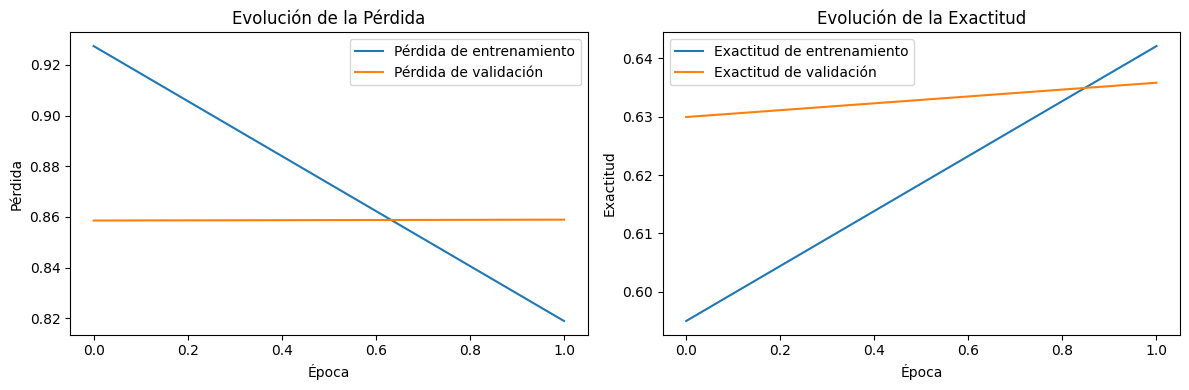

Configuraciones Roberta: 100%|██████████| 1/1 [11:16:56<00:00, 40616.50s/cfg]


In [26]:
# Directorio raíz para almacenar los logs y modelos de Roberta
LOG_ROOT = drive_root / "tuner_logs_roberta_3"
LOG_ROOT.mkdir(exist_ok=True)

BATCH_SIZE = 16

for cfg in tqdm(ROBERTA_EXPERIMENTS, desc="Configuraciones Roberta", unit="cfg"):
    print(f"\n🔎 Entrenando configuración – {cfg['name']}")

    # Preparación del conjunto de datos
    train_ds, val_ds, test_ds, cw, num_classes, max_len, features = prepare_data(cfg, "yelp_reviews_xxl.parquet", 500_000)
    # sanity_check_prepare_data(train_ds, val_ds, test_ds, cw, num_classes, max_len, features)
    print()

    # Roberta espera textos crudos (no enteros)
    # Convertimos datasets a batches y prefetch, pero SIN vectorización manual
    def to_text_batches(ds):
        return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    train_ds_batched = to_text_batches(train_ds)
    val_ds_batched   = to_text_batches(val_ds)
    test_ds_batched  = to_text_batches(test_ds)

    # Directorio del experimento actual
    exp_dir = LOG_ROOT / cfg["name"]
    models_dir = exp_dir / "models"
    models_dir.mkdir(parents=True, exist_ok=True)

    # Constructor de modelo Roberta
    model = build_roberta_model(
        max_length=max_len,
        num_classes=num_classes,
        learning_rate=3e-5,
        preset="roberta_base_en"
    )
    print(model.summary())

    # Callback de parada temprana
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
    logs = tf.keras.callbacks.TensorBoard(log_dir=f"{str(exp_dir)}/tb_logs")

    # Entrenamiento
    history = model.fit(
        train_ds_batched,
        validation_data=val_ds_batched,
        epochs=2,
        class_weight=cw if cw else None,
        callbacks=[early_stopping, logs],
        verbose=2
    )

    # Evaluación en test
    result = model.evaluate(test_ds_batched, verbose=1)

    # Obtener etiquetas reales y predichas
    y_true = np.concatenate([y.numpy() for _, y in test_ds_batched], axis=0)
    y_pred_probs = model.predict(test_ds_batched)
    if num_classes == 1:
        y_pred = (y_pred_probs > 0.5).astype("int32").flatten()
    else:
        y_pred = np.argmax(y_pred_probs, axis=1)

    # Guardar métricas y gráficos
    evaluate_from_predictions(y_true, y_pred, num_classes, output_dir=models_dir)

    # Guardar resultados de test
    with open(models_dir / "test_results.txt", "w") as f:
        f.write(f"Test Loss: {result[0]:.4f} — Test Accuracy: {result[1]:.4f}\n")

    # Guardar el modelo Roberta entrenado
    model.save(str(models_dir / f"{cfg['name']}_roberta_model.h5"))
    model.save(str(models_dir / f"{cfg['name']}_roberta_model.keras"))

    # Graficar entrenamiento
    plot_training(history, models_dir / "training_plot.png")